# Supplementary Figure S6b. S-LDSC of split-specific trans-MaxPIP annotations

Heritability enrichment (top) and marginal τ* (bottom) of the TransMap-eGene, TransMap-local and TransMap-global trans-MaxPIP annotations built separately from each 50:50 donor split. Panel layout follows `Manu_Figures/Figure_Calibration.ipynb` cell 13.

Error bars are estimate ± 1.96 × SE (95% CI), as drawn by the source helpers `plotEnrichForest` / `plotTauForest` (sldsc_utils.R). Significance symbols follow the source `pToSymbol`: **** P < 1e-4, *** P < 1e-3, ** P < 0.01, * P < 0.05, . P < 0.1, shown only when the estimate is > 0 (also for enrichment, whose null is 1). P-values are nominal and two-sided; no multiple-testing correction is applied (the rds also carries `fdr_bh`, a Benjamini–Hochberg adjustment across all tests of the same metric in the panel, for reference only). Dashed lines: 1 for enrichment, 0 for τ*. All S-LDSC values are random-effects meta-analyses across traits (57 all, 18 brain, 22 blood; per-trait models conditional on the 53 baseline-LD annotations), recomputed here from the per-trait S-LDSC outputs with a re-implementation of the author's meta-analysis code.

Integrity note: the source notebook reads `potential_artifact/SLDSC_Spit_sample_analysis.rds`, which `Spit_sample_analysis.ipynb` cells 61-62 altered after the meta-analysis: +1 was added to the TransMap-local (Split 2) enrichment and +0.1 to its marginal τ* in all three trait groups, and P-values/symbols were recomputed from the altered estimates. The values here are the unaltered meta-analysis results (they match the saved rds exactly for the other 15 rows of each metric). With the real values TransMap-local (Split 2) has enrichment 1.94 (all traits, P = 3.2e-4), 1.59 (blood, P = 0.78) and 2.35 (brain, P = 4.6e-6), and marginal τ* 0.094 (all), 0.049 (blood, P = 0.18) and 0.145 (brain), instead of the published 2.94 / 2.59 / 3.35 and 0.194 / 0.149 / 0.245.

Input: `data/Figure_S6b_split_sldsc.rds`.

In [1]:
library(ggplot2)
library(patchwork)
d <- readRDS("data/Figure_S6b_split_sldsc.rds")
d

metric,trait_set,trait,scale,split,annotation,annotation_raw,est,se,pvalue,fdr_bh,n_traits
<fct>,<chr>,<fct>,<fct>,<chr>,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
Enrichment,all_traits,All traits (57),TransMap-eGene,Split1,TransMap-eGene (Split1),Split1_eGene_SuSiE,3.079102969,0.12011774,6.449023e-23,1.160824e-21,57
Enrichment,blood_traits,Blood-related traits (22),TransMap-eGene,Split1,TransMap-eGene (Split1),Split1_eGene_SuSiE,2.615682401,0.19099753,8.042303e-07,2.068021e-06,22
Enrichment,brain_traits,Brain-related traits (18),TransMap-eGene,Split1,TransMap-eGene (Split1),Split1_eGene_SuSiE,3.701468534,0.20264210,1.023025e-10,3.682892e-10,18
Enrichment,all_traits,All traits (57),TransMap-eGene,Split2,TransMap-eGene (Split2),Split2_eGene_SuSiE,2.928529018,0.12376217,2.904047e-21,2.613642e-20,57
Enrichment,blood_traits,Blood-related traits (22),TransMap-eGene,Split2,TransMap-eGene (Split2),Split2_eGene_SuSiE,2.606449187,0.18383251,4.611929e-06,9.223857e-06,22
Enrichment,brain_traits,Brain-related traits (18),TransMap-eGene,Split2,TransMap-eGene (Split2),Split2_eGene_SuSiE,3.458135847,0.20618509,1.803936e-10,5.411807e-10,18
Enrichment,all_traits,All traits (57),TransMap-local,Split1,TransMap-local (Split1),Split1_Local_SuSiE,2.972791145,0.15808335,7.349987e-19,4.409992e-18,57
Enrichment,blood_traits,Blood-related traits (22),TransMap-local,Split1,TransMap-local (Split1),Split1_Local_SuSiE,2.230434339,0.20630580,3.904504e-05,7.028107e-05,22
Enrichment,brain_traits,Brain-related traits (18),TransMap-local,Split1,TransMap-local (Split1),Split1_Local_SuSiE,3.815031713,0.22167647,7.468188e-11,3.360685e-10,18


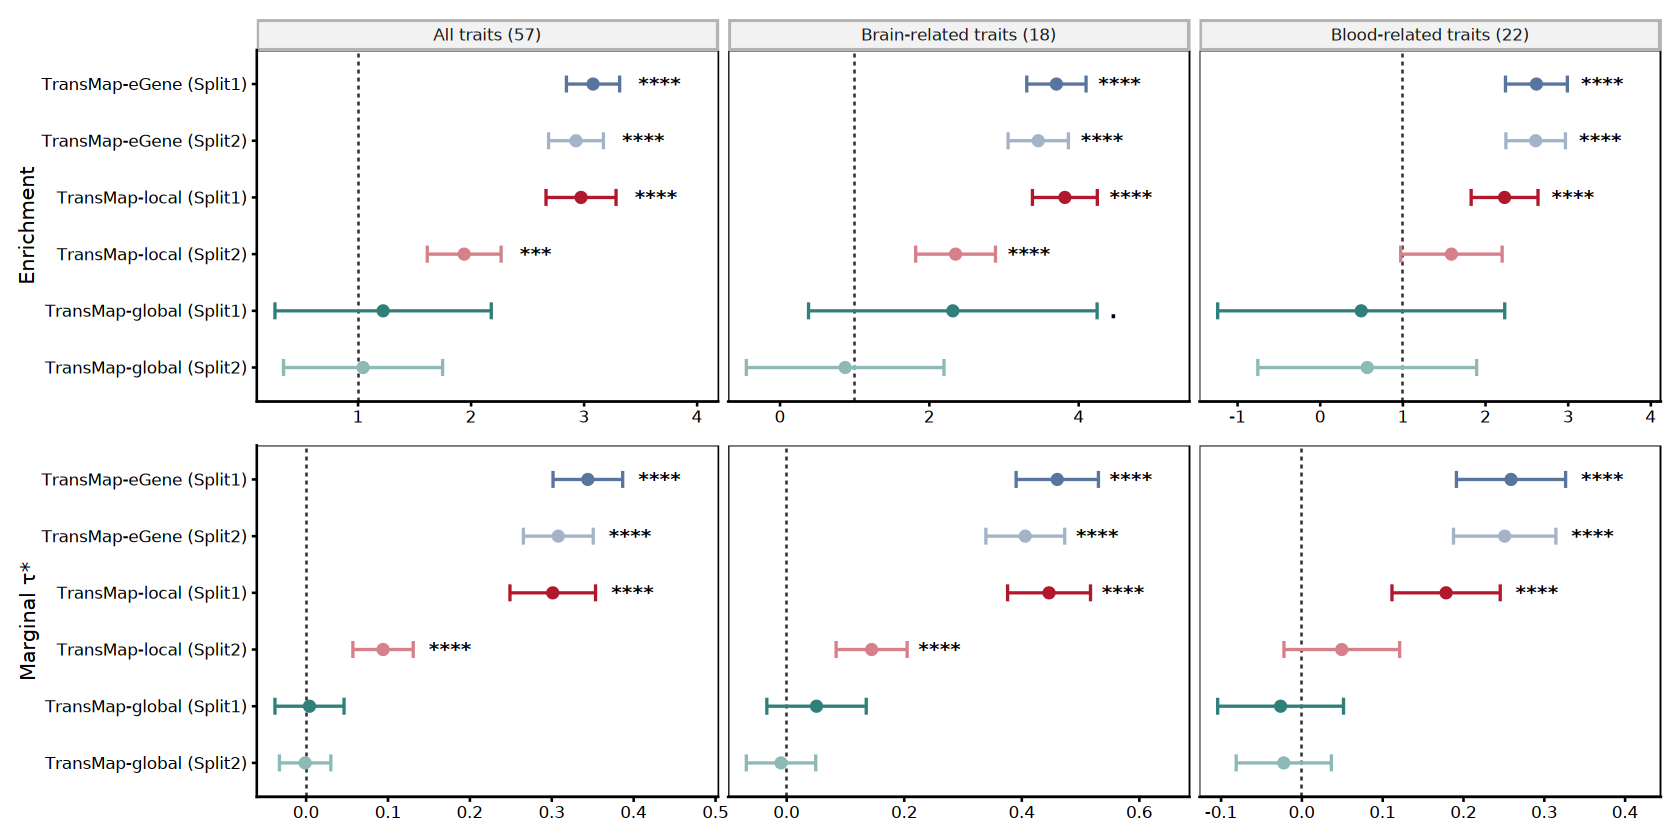

In [2]:
p_sym <- function(p, est) {
  s <- c("****", "***", "**", "*", ".", "")[findInterval(p, c(0, 1e-4, 1e-3, 0.01, 0.05, 0.1, Inf), rightmost.closed = TRUE)]
  ifelse(est > 0, s, "")
}
forest <- function(d, cols, ylab, vline, show_strip = TRUE) {
  d$lo <- d$est - 1.96 * d$se; d$hi <- d$est + 1.96 * d$se
  d$sym <- p_sym(d$pvalue, d$est)
  pad <- 0.03 * diff(range(c(d$lo, d$hi, vline)))
  p <- ggplot(d, aes(y = annotation, colour = annotation)) +
    geom_vline(xintercept = vline, linetype = "dashed", colour = "grey20") +
    geom_errorbar(aes(xmin = lo, xmax = hi), width = 0.3, orientation = "y", linewidth = 0.7) +
    geom_point(aes(x = est), size = 2.6) +
    geom_text(aes(x = hi + pad, label = sym), colour = "black", hjust = 0, size = 4.2, fontface = "bold") +
    facet_grid(. ~ trait, scales = "free_x") +
    scale_colour_manual(values = cols, guide = "none") +
    scale_y_discrete(limits = rev) +
    scale_x_continuous(expand = expansion(mult = c(0.05, 0.22))) +
    labs(x = NULL, y = ylab) +
    theme_classic(base_size = 12) +
    theme(strip.background = element_rect(fill = "grey95", colour = "grey70"),
          panel.border = element_rect(colour = "black", fill = NA, linewidth = 0.4))
  if (!show_strip) p <- p + theme(strip.text = element_blank(), strip.background = element_blank())
  p
}

cols <- c("TransMap-eGene (Split1)" = "#58769D", "TransMap-eGene (Split2)" = "#A3B4C9",
          "TransMap-local (Split1)" = "#B2182B", "TransMap-local (Split2)" = "#D5808A",
          "TransMap-global (Split1)" = "#2F7F7B", "TransMap-global (Split2)" = "#8DB9B6")
rows <- list(forest(subset(d, metric == "Enrichment"), cols, "Enrichment", 1, TRUE),
             forest(subset(d, metric == "Marginal tau*"), cols, expression("Marginal " * tau * "*"), 0, FALSE))
options(repr.plot.width = 14, repr.plot.height = 7)
wrap_plots(rows, ncol = 1)